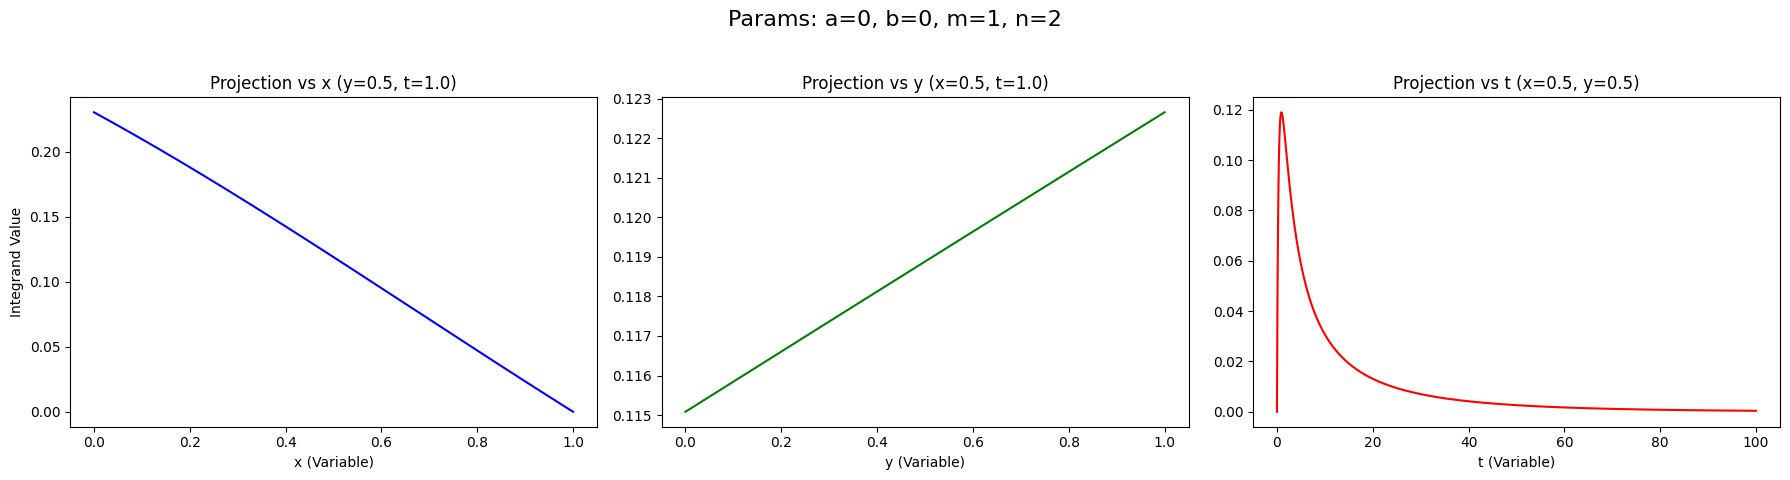

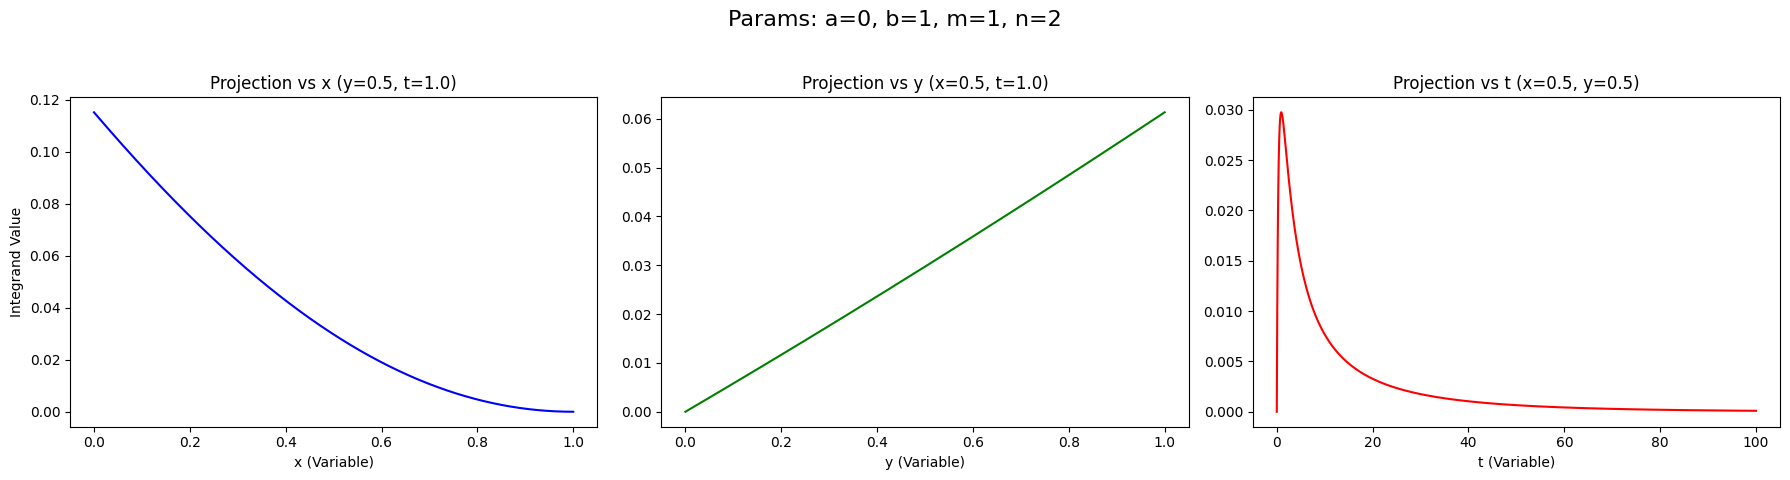

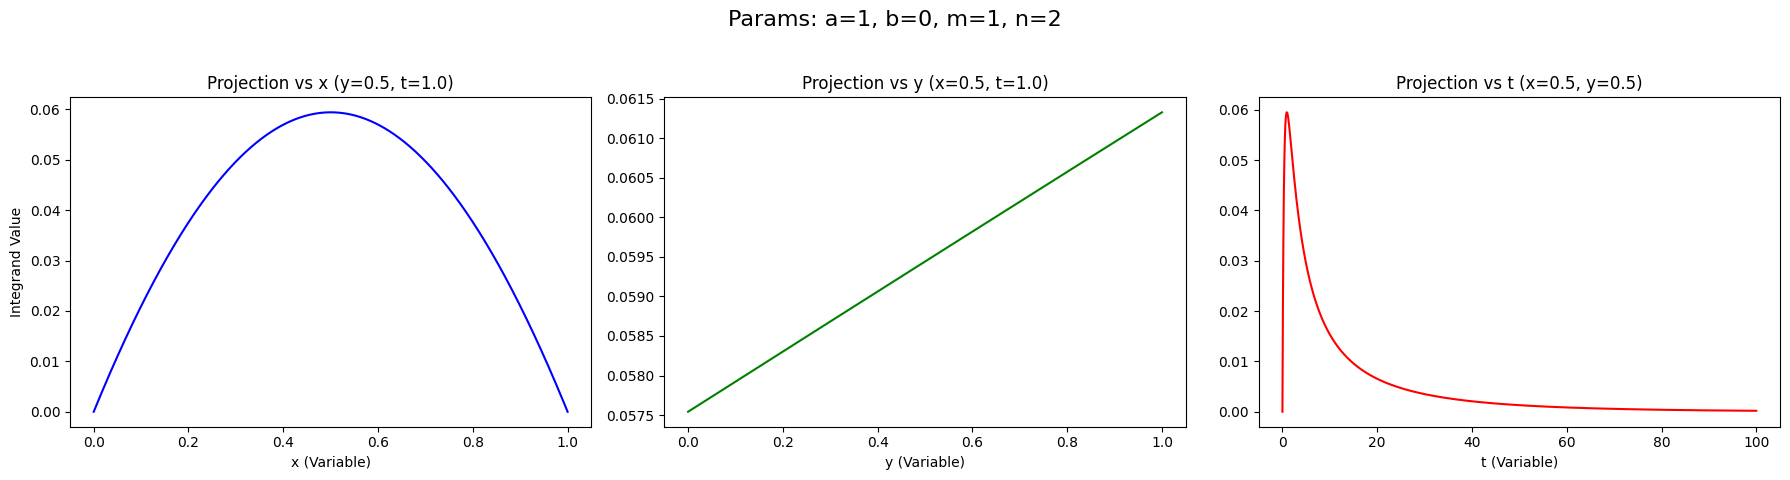

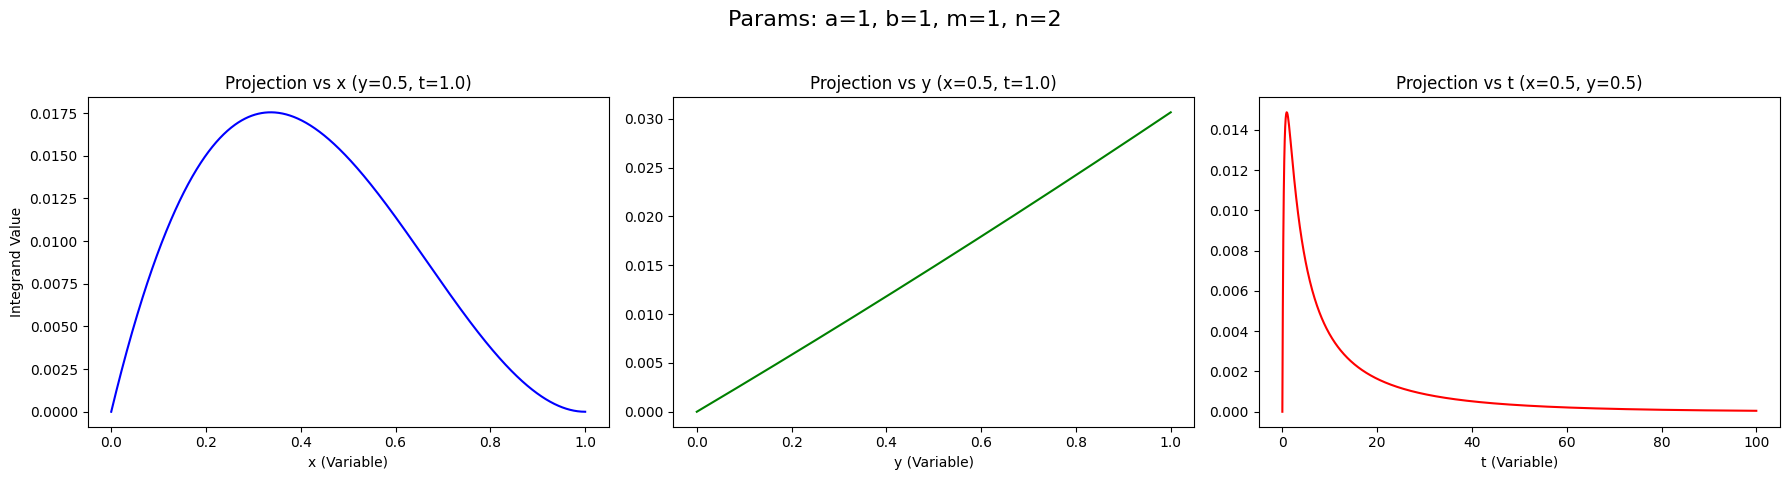

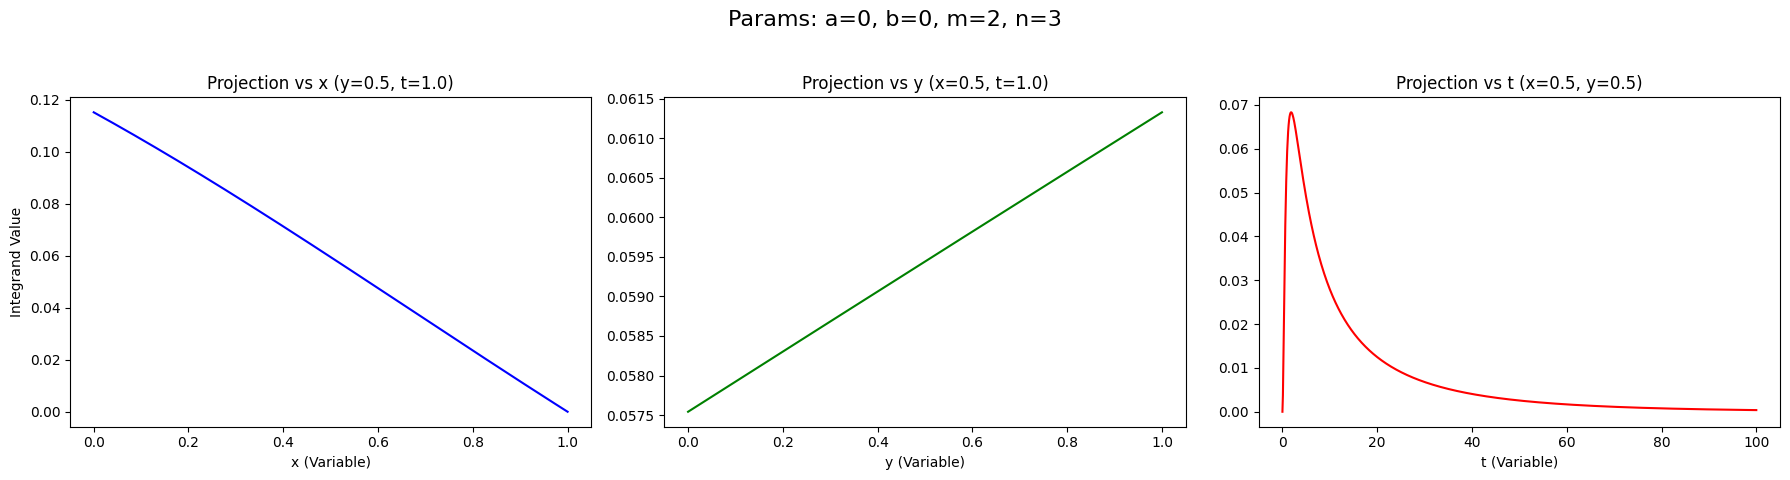

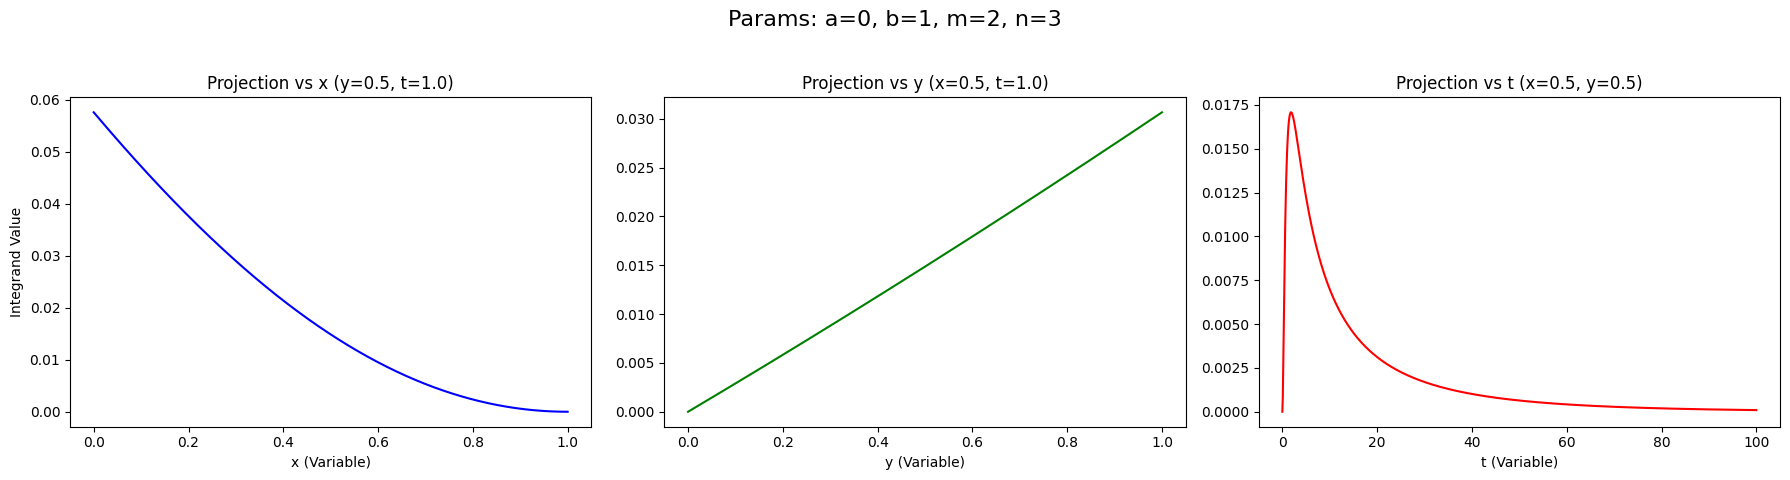

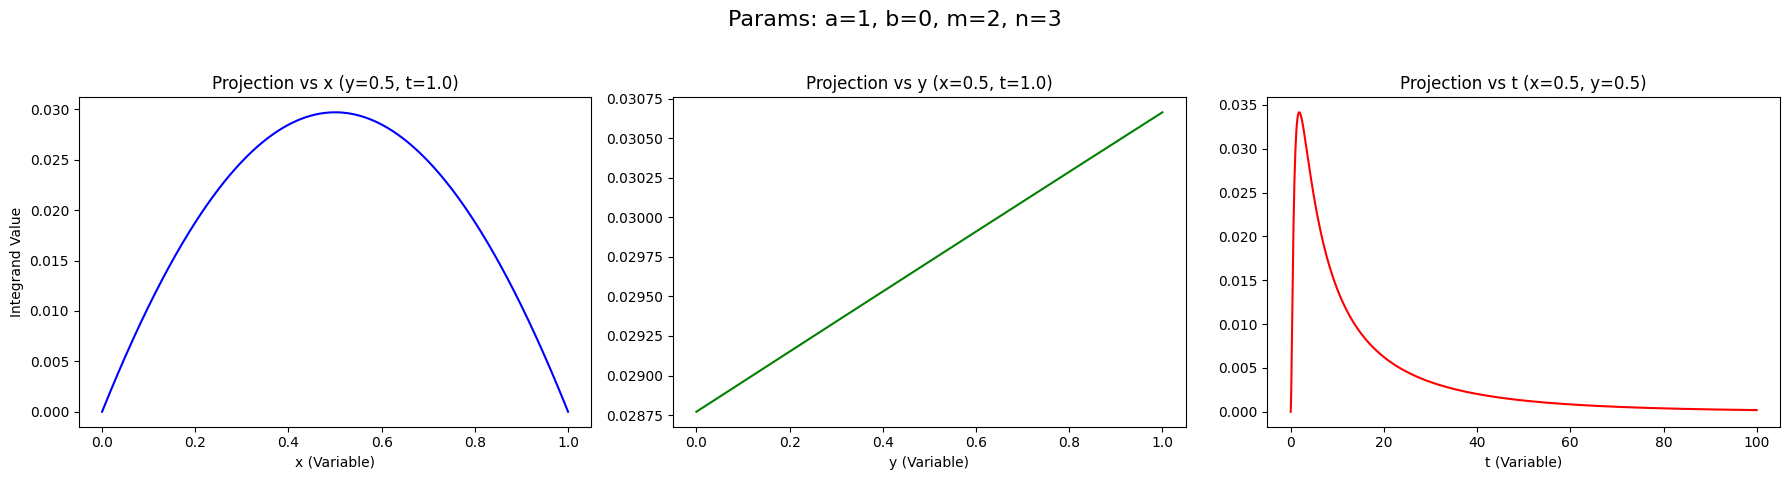

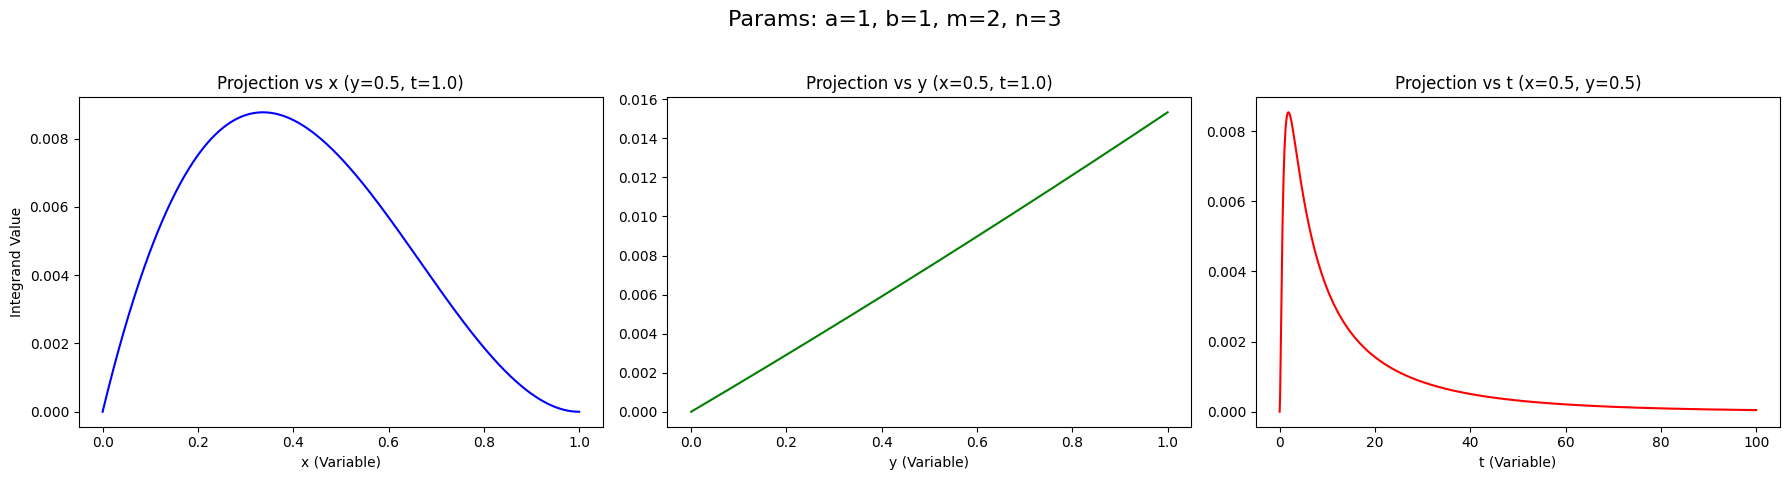

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

la = 1.0
m1 = m2 = m3 = 0.3 / la
p1p1 = p2p2 = -(0.14 / la) ** 2
PP = -(0.7 / la) ** 2

A_VALS = [0, 0, 1, 1, 0, 0, 1, 1]
B_VALS = [0, 1, 0, 1, 0, 1, 0, 1]
M_VALS = [1, 1, 1, 1, 2, 2, 2, 2]
N_VALS = [2, 2, 2, 2, 3, 3, 3, 3]

def integrand_xyz(x, y, t, a, b, m, n):
    alp1 = x
    alp2 = y * (1.0 - x)
    RR = alp1**2 * p1p1 + alp2**2 * p2p2 - alp1 * alp2 * (PP - p1p1 - p2p2)
    DD = alp1 * (p1p1 + m1**2) + alp2 * (p2p2 + m2**2) + (1 - alp1 - alp2) * m3**2 - RR
    z0 = t * DD + (t / (1 + t)) * RR
    return alp1**a * alp2**b * (1 - x) * t**m / (1 + t)**n * np.exp(-z0)

x_space = np.linspace(0., 1., 1000)
y_space = np.linspace(0., 1., 1000)
t_space = np.linspace(0., 100.0, 1000)

for i in range(len(A_VALS)):
    a, b, m, n = A_VALS[i], B_VALS[i], M_VALS[i], N_VALS[i]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f'Params: a={a}, b={b}, m={m}, n={n}', fontsize=16)

    vals_x = integrand_xyz(x_space, 0.5, 1.0, a, b, m, n)
    axes[0].plot(x_space, vals_x, color='blue')
    axes[0].set_xlabel('x (Variable)')
    axes[0].set_ylabel('Integrand Value')
    axes[0].set_title('Projection vs x (y=0.5, t=1.0)')

    vals_y = integrand_xyz(0.5, y_space, 1.0, a, b, m, n)
    axes[1].plot(y_space, vals_y, color='green')
    axes[1].set_xlabel('y (Variable)')
    axes[1].set_title('Projection vs y (x=0.5, t=1.0)')

    vals_t = integrand_xyz(0.5, 0.5, t_space, a, b, m, n)
    axes[2].plot(t_space, vals_t, color='red')
    axes[2].set_xlabel('t (Variable)')
    axes[2].set_title('Projection vs t (x=0.5, y=0.5)')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

In [2]:
grid_size = 25
x_space = np.linspace(0., 1., grid_size)
y_space = np.linspace(0., 1., grid_size)
t_space = np.linspace(0., 100., grid_size)

for i in range(len(A_VALS)):
    a, b, m, n = A_VALS[i], B_VALS[i], M_VALS[i], N_VALS[i]

    fig = make_subplots(
        rows=1, cols=3,
        specs=[[{'type': 'surface'}, {'type': 'surface'}, {'type': 'surface'}]],
        subplot_titles=(f'f(x, y) [t=1.0]', f'f(x, t) [y=0.5]', f'f(y, t) [x=0.5]')
    )

    X, Y = np.meshgrid(x_space, y_space)
    Z1 = integrand_xyz(X, Y, 1.0, a, b, m, n)
    fig.add_trace(go.Surface(z=Z1, x=X, y=Y, colorscale='Viridis', showscale=False), row=1, col=1)

    X2, T2 = np.meshgrid(x_space, t_space)
    Z2 = integrand_xyz(X2, 0.5, T2, a, b, m, n)
    fig.add_trace(go.Surface(z=Z2, x=X2, y=T2, colorscale='Plasma', showscale=False), row=1, col=2)

    Y3, T3 = np.meshgrid(y_space, t_space)
    Z3 = integrand_xyz(0.5, Y3, T3, a, b, m, n)
    fig.add_trace(go.Surface(z=Z3, x=Y3, y=T3, colorscale='Inferno', showscale=False), row=1, col=3)

    fig.update_layout(
        title=f'Params: a={a}, b={b}, m={m}, n={n}',
        scene=dict(xaxis_title='x', yaxis_title='y', zaxis_title='f'),
        scene2=dict(xaxis_title='x', yaxis_title='t', zaxis_title='f'),
        scene3=dict(xaxis_title='y', yaxis_title='t', zaxis_title='f'),
        height=600,
        width=1500
    )

    fig.show()

In [3]:
grid_size = 25
x_space = np.linspace(0., 1., grid_size)
y_space = np.linspace(0., 1., grid_size)
t_space = np.linspace(0., 100., grid_size)

X, Y, T = np.meshgrid(x_space, y_space, t_space, indexing='ij')

for i in range(len(A_VALS)):
    a, b, m, n = A_VALS[i], B_VALS[i], M_VALS[i], N_VALS[i]

    Z = integrand_xyz(X, Y, T, a, b, m, n)

    flat_X = X.flatten()
    flat_Y = Y.flatten()
    flat_T = T.flatten()
    flat_Z = Z.flatten()

    fig = go.Figure(data=go.Volume(
        x=flat_T,
        y=flat_X,
        z=flat_Y,
        value=flat_Z,
        isomin=flat_Z.min() + (flat_Z.max() - flat_Z.min()) * 0.1,
        isomax=flat_Z.max(),
        opacity=0.2,
        surface_count=20,
        colorscale='Inferno',
        caps=dict(x_show=False, y_show=False, z_show=False)
    ))

    fig.update_layout(
        title=f'4D Cube Volume: Set {i+1} (a={a}, b={b}, m={m}, n={n})',
        scene=dict(
            xaxis_title='t (Horizontal)',
            yaxis_title='x (Horizontal)',
            zaxis_title='y (Vertical)',
            aspectmode='cube'
        ),
        margin=dict(l=0, r=0, b=0, t=40),
        height=700
    )

    fig.show()